In [5]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 3.1 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.5 MB 5.6 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.5 MB 4.8 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.5 MB 4.1 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.5 MB 4.3 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.5 MB 3.5 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.5 MB 3.5 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.5 MB 3.5 MB/s eta 0:00:02
   -------------------------- ------------- 6.3/9.5 MB 3.5 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.5 MB 3.7 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.5 MB 3.8 MB/s eta 0:00:01
   ------------------------------------- -- 8.9/9.5 MB 3.9 MB/s eta 0:00:01
   ----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [8]:
!pip install numpy
!pip install pandas
import numpy as np
import pandas as pd


In [2]:

import pandas as pd
#Given a CSV file containing Zomato restaurant ratings, use pandas to detect outliers in the 'user_rating' column using the IQR method and print the indices of the detected outliers.

data = {
    'restaurant_name': [
        'A', 'B', 'C', 'D', 'E',
        'F', 'G', 'H', 'I', 'J'
    ],
    'user_rating': [
        3.5, 4.0, 3.8, 4.2, 3.9,
        4.1, 3.7, 4.0, 1.0, 5.0
    ]
}

df = pd.DataFrame(data)

df.to_csv('zomato_ratings.csv', index=False)
df = pd.read_csv('zomato_ratings.csv')

#print(df)
Q1 = df['user_rating'].quantile(0.25)

Q3 = df['user_rating'].quantile(0.75)

IQR = Q3 - Q1

#print("Q1:", Q1)
#print("Q3:", Q3)
#print("IQR:", IQR)
lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

#print("Lower Limit:", lower_limit)
#print("Upper Limit:", upper_limit)
outliers = df[
    (df['user_rating'] < lower_limit) |
    (df['user_rating'] > upper_limit)
]

print("Outlier Indices:")
print(outliers.index.tolist())

Outlier Indices:
[8, 9]


    order_amount
0            150
1            200
2            250
3            300
4            180
5            220
6            270
7            350
8            400
9            190
10           210
11           280
12           320
13           250
14          1500
15          1800


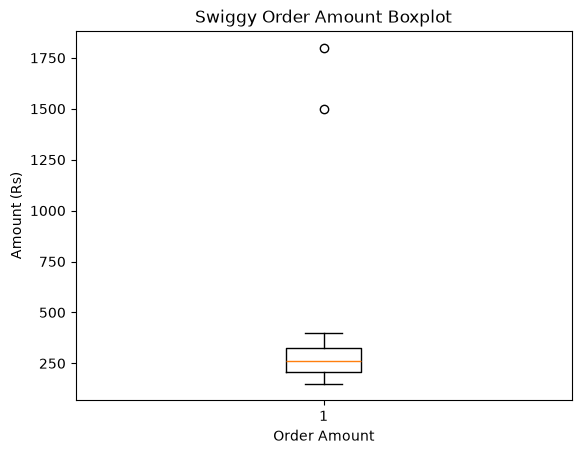

In [6]:
#Create a boxplot for the 'order_amount' column from a Swiggy orders dataset using matplotlib, and visually identify any outliers present.<br><br><em><strong>Hint:</strong> Use plt.boxplot() and label your axes for clarity.</em>
import matplotlib.pyplot as plt
data = {
    'order_amount': [
        150, 200, 250, 300, 180,
        220, 270, 350, 400, 190,
        210, 280, 320, 250, 1500,
        1800
    ]
}

df = pd.DataFrame(data)

print(df)
plt.boxplot(df['order_amount'])

plt.title('Swiggy Order Amount Boxplot')
plt.xlabel('Order Amount')
plt.ylabel('Amount (Rs)')

plt.show()

In [9]:
#Apply winsorization to the 'transaction_amount' column in a Paytm transactions DataFrame to cap all values above the 95th percentile and below the 5th percentile, then display the updated column statistics.
data = {
    'transaction_amount': [
        100, 200, 300, 400, 500,
        600, 700, 800, 900, 1000,
        1200, 1500, 2000, 5000, 10000
    ]
}

df = pd.DataFrame(data)

lower_limit = df['transaction_amount'].quantile(0.05)

upper_limit = df['transaction_amount'].quantile(0.95)

#print("5th Percentile:", lower_limit)
#print("95th Percentile:", upper_limit)
df['transaction_amount'] = np.clip(
    df['transaction_amount'],
    lower_limit,
    upper_limit
)

print(df['transaction_amount'].describe())

count      15.000000
mean     1451.333333
std      1836.405132
min       170.000000
25%       450.000000
50%       800.000000
75%      1350.000000
max      6500.000000
Name: transaction_amount, dtype: float64


In [10]:
#You have a DataFrame of Flipkart product prices stored as strings with currency symbols (e.g., '₹1,299'). Convert this column to numeric type using pandas, ensuring all non-numeric characters are removed.<br><br><em><strong>Hint:</strong> Use str.replace() and astype().</em>
data = {
    'product_name': ['Mobile', 'Laptop', 'Shoes', 'Watch', 'Headphones'],
    'price': ['₹1,299', '₹45,999', '₹2,499', '₹3,000', '₹1,599']
}

df = pd.DataFrame(data)

df['price'] = df['price'].str.replace('₹', '', regex=False)

df['price'] = df['price'].str.replace(',', '', regex=False)

df['price'] = df['price'].astype(int)

print(df.dtypes)

product_name      str
price           int64
dtype: object


In [11]:
#Fix the following code snippet where the 'is_premium' column in a Spotify user DataFrame is a mix of boolean, string, and integer types. Convert the entire column to boolean type, treating 'True', 1, and 'yes' as True, and everything else as False.
import pandas as pd

data = {
    'user_id': [101, 102, 103, 104, 105, 106],
    'is_premium': [True, 'True', 1, 'yes', 'No', 0]
}

df = pd.DataFrame(data)

df['is_premium'] = df['is_premium'].apply(
    lambda x: str(x).strip().lower() in ['true', '1', 'yes']
)

print(df)
print(df.dtypes)

   user_id  is_premium
0      101        True
1      102        True
2      103        True
3      104        True
4      105       False
5      106       False
user_id       int64
is_premium     bool
dtype: object
